### Sentinel-3数据查看

In [4]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import xarray as xr  
import numpy as np
import rasterio as rio
from pyrsimg import imgShow, dt64_to_dyr


In [5]:
## s3 data
# path_s3l2 = 'data/s3_atl/S3A_SR_2_LAN_HY_20261001T032409_20261001T033227_20261001T054140_0498_144_289______PS1_O_NR_005.SEN3/standard_measurement.nc'
path_s3l2 = 'data/s3_atl/S3A_SR_2_LAN_HY_20261001T032409_20261001T033227_20261001T054140_0498_144_289______PS1_O_NR_005.SEN3/enhanced_measurement.nc'
## remote sensing data
path_rsimg = 'data/rsimg/s2_20251206_reproj2wgs84.tif'



In [6]:
## 1. s3l2 altimetry data
# s3l2 = nc.Dataset(path_s3l2)   ##
s3l2 = xr.open_dataset(path_s3l2)
## 2. remote sensing image
rsimg = rio.open(path_rsimg)
rsimg_arr = rsimg.read().transpose(1, 2, 0)


In [7]:
print('number of variables: ', len(s3l2.variables.keys()))
list(s3l2.variables.keys())


number of variables:  298


['time_01',
 'time_20_ku',
 'time_20_c',
 'echo_sample_ind',
 'wf_sample_ind',
 'max_multi_stack_ind',
 'UTC_day_01',
 'UTC_sec_01',
 'UTC_day_20_ku',
 'UTC_sec_20_ku',
 'UTC_day_20_c',
 'UTC_sec_20_c',
 'UTC_time_1hz_20_ku',
 'UTC_time_1hz_20_c',
 'lat_01',
 'lon_01',
 'lat_20_ku',
 'lon_20_ku',
 'lat_20_c',
 'lon_20_c',
 'surf_type_20_ku',
 'surf_type_20_c',
 'surf_class_01',
 'surf_class_20_ku',
 'surf_class_20_c',
 'rad_surf_type_01',
 'angle_coast_20_ku',
 'dist_coast_20_ku',
 'oltc_target_type_20_ku',
 'oltc_target_nadir_20_ku',
 'waveform_class_rank1_20_ku',
 'waveform_class_prob_rank1_20_ku',
 'waveform_class_rank2_20_ku',
 'waveform_class_prob_rank2_20_ku',
 'alt_20_ku',
 'alt_20_c',
 'orb_alt_rate_20_ku',
 'orb_alt_rate_20_c',
 'tracker_range_20_ku',
 'tracker_range_20_c',
 'tracker_range_20_plrm_ku',
 'h0_nav_dem_20_ku',
 'agc_20_ku',
 'agc_20_c',
 'agc_20_plrm_ku',
 'agc_qual_20_ku',
 'agc_qual_20_c',
 'agc_qual_20_plrm_ku',
 'scale_factor_20_ku',
 'scale_factor_20_c',
 'sc

In [8]:
lat_20_ku = s3l2['lat_20_ku'][:]
lon_20_ku = s3l2['lon_20_ku'][:]
time_20_ku = s3l2['time_20_ku'][:]
waveform_20_ku = s3l2['waveform_20_ku'][:]
time_20_ku = dt64_to_dyr(time_20_ku.values)   ### seconds to year.
print(time_20_ku.shape)
print(waveform_20_ku.shape)
time_20_ku


(9405,)
(9405, 256)


array([2026.74794521, 2026.74794521, 2026.74794521, ..., 2026.74794521,
       2026.74794521, 2026.74794521])

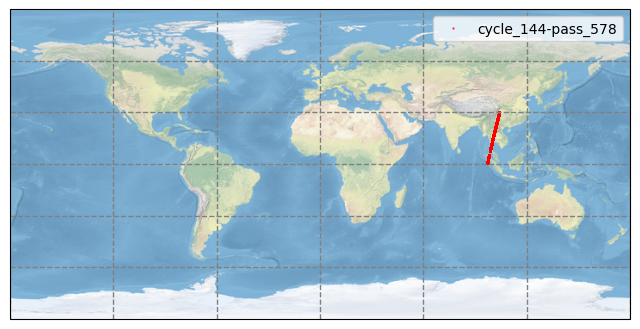

In [9]:
proj = ccrs.PlateCarree(central_longitude=0.0)
fig = plt.figure(figsize=(8,8))  ## 定义画布
ax = fig.add_subplot(111, projection=proj);   ## 定义画框
ax.stock_img()    ## 加载地图
orbit = 'cycle_'+str(s3l2.cycle_number)+'-pass_'+str(s3l2.pass_number)
ax.plot(lon_20_ku, lat_20_ku, marker='.', markersize=1,
                                linewidth=0.0, label=orbit, color='red')
ax.gridlines(linewidth=1, color='gray', linestyle='--')
ax.legend()



Text(0.5, 1.0, 'sentinel-3 data')

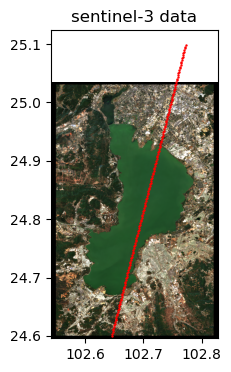

In [12]:
rsimg_extent = [rsimg.bounds[0], rsimg.bounds[2], rsimg.bounds[1], rsimg.bounds[3]]  ## left, right, bottom, top
ids = np.where((lat_20_ku[:]>24.6) & (lat_20_ku[:]<25.1))  ### the range of dianchi
fig = plt.figure(figsize=(4, 4))
ax = plt.subplot(1,1,1)
imgShow(rsimg_arr, extent=rsimg_extent, ax=ax)
plt.scatter(x=lon_20_ku[ids], y=lat_20_ku[ids], s=0.5, color='red')  ## altimetry data
plt.title('sentinel-3 data')


### Check retracked surface elevation value.

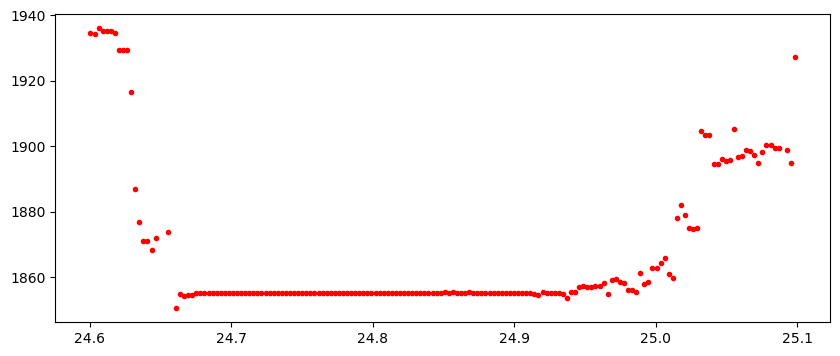

In [13]:
## 3.3 ocog retracker(official given)
h_cor_ocog = s3l2['elevation_ocog_20_ku'][:]
plt.figure(figsize=(10,4))
plt.plot(lat_20_ku[ids], h_cor_ocog[ids], 'r.')
# plt.ylim(1854.5, 1855.6)


#### Check the waveform (脉冲有限 VS. 合成孔径雷达)

In [14]:
ids = np.where((lat_20_ku[:]>24.8) & (lat_20_ku[:]<24.81))[0]  ### the range of dianchi
id = ids[1]
wf_sar = s3l2['waveform_20_ku'][:][id]
wf_lrm = s3l2['waveform_20_plrm_ku'][:][id]
print(wf_sar.shape)
print(wf_lrm.shape)


(256,)
(128,)


Text(0.5, 1.0, 'lrm waveform')

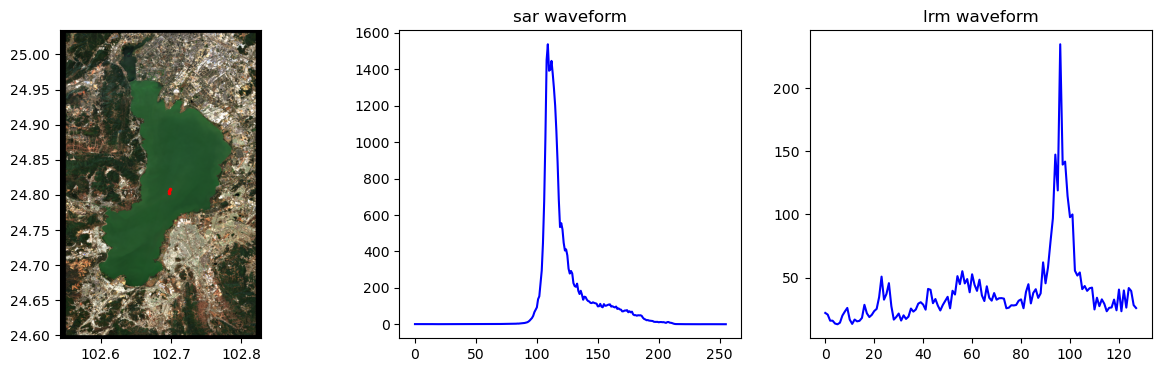

In [17]:
fig, ax = plt.subplots(1,3, figsize=(15,4))
imgShow(rsimg_arr, extent=rsimg_extent, ax=ax[0])
ax[0].scatter(x=lon_20_ku[ids], y=lat_20_ku[ids], s=2.5, color='red')  ## altimetry data
ax[1].plot(wf_sar, color='blue')
ax[1].set_title('sar waveform')
ax[2].plot(wf_lrm, color='blue')
ax[2].set_title('lrm waveform')

